Whoop analyse 

In [ ]:
# Settings and Libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates 

JOURS_CALIBRATION = 14   # premiers jours ignorés : Whoop se calibre
JOURS_REF = 60           # longueur de la référence pour la zone normale
K_SD = 0.5               # largeur de la zone normale : ± K_SD écart-type

# figures's colors
ROUGE, JAUNE, VERT = "#D64545", "#E3B23C", "#3E9E5C"
ENCRE, GRIS = "#1F2328", "#9AA3AD"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})


In [24]:
# import data
brut = pd.read_csv('/Users/lucas1/Desktop/School/AMU - STAPS/Whoop/my_whoop_data_2026_11_02/physiological_cycles.csv')
print(f"{brut.shape[0]} lignes, {brut.shape[1]} colonnes")
brut.head()

528 lignes, 26 colonnes


,Heure de début du cycle,Heure de fin du cycle,Fuseau horaire du cycle,Score de récupération %,Fréquence cardiaque au repos (bpm),Variabilité de la fréquence cardiaque (ms),Température cutanée (Celsius),Niveau d'oxygène %,Effort du jour,Dépense énergétique (cal.),...,Durée du sommeil (min),Temps passé au lit (min),Durée du sommeil léger (min),Durée du sommeil profond (min),Durée du sommeil paradoxal (min),Temps d'éveil (min),Besoins en sommeil (min),Dette de sommeil (min),Efficacité du sommeil %,Régularité du sommeil %
0,2026-11-02 01:27:14,NaN,UTC+01:00,25.0,53.0,103.0,33.77,96.00,NaN,NaN,...,263.0,307.0,108.0,110.0,45.0,44.0,574.0,102.0,85.0,71.0
1,2026-10-31 23:29:40,2026-11-02 01:27:14,UTC+01:00,64.0,49.0,126.0,33.18,97.82,6.3,2448.0,...,454.0,506.0,242.0,108.0,104.0,52.0,614.0,127.0,90.0,79.0
2,2026-10-31 00:01:09,2026-10-31 23:29:40,UTC+01:00,69.0,46.0,147.0,33.06,97.60,12.0,2691.0,...,293.0,378.0,136.0,98.0,59.0,85.0,559.0,89.0,77.0,68.0
3,2026-10-30 01:41:07,2026-10-31 00:01:09,UTC+01:00,91.0,47.0,148.0,33.63,97.21,4.3,2040.0,...,347.0,383.0,199.0,88.0,60.0,36.0,527.0,44.0,90.0,67.0
4,2026-10-28 22:58:35,2026-10-30 01:41:07,UTC+01:00,60.0,48.0,122.0,33.94,97.18,10.9,2836.0,...,426.0,518.0,246.0,72.0,108.0,92.0,515.0,0.0,82.0,85.0


In [25]:

# understanding of the columns, one ligne means one sleeping and not a day
apercu = pd.DataFrame({
    "type": brut.dtypes.astype(str),
    "valuers non vides": brut.notna().sum(),
    "% vide": (100 * brut.isna().mean()).round(1),
    "exemple": brut.iloc[0],
})
apercu


,type,valuers non vides,% vide,exemple
Heure de début du cycle,object,528,0.0,2026-11-02 01:27:14
Heure de fin du cycle,object,527,0.2,NaN
Fuseau horaire du cycle,object,528,0.0,UTC+01:00
Score de récupération %,float64,522,1.1,25.0
Fréquence cardiaque au repos (bpm),float64,522,1.1,53.0
Variabilité de la fréquence cardiaque (ms),float64,522,1.1,103.0
Température cutanée (Celsius),float64,522,1.1,33.77
Niveau d'oxygène %,float64,521,1.3,96.0
Effort du jour,float64,527,0.2,NaN
Dépense énergétique (cal.),float64,527,0.2,NaN


In [34]:
# We gonna keep the columns we need and short them 
import re
import unicodedata

a_garder = {
    "debut_cycle": ["Heure de début du cycle"],
    "reveil": ["Premiers signes de réveil"],
    "recovery": ["Score de récupération %"],
    "hrv_ms": ["Variabilité de la fréquence cardiaque (ms)"],
    "fc_repos": ["Fréquence cardiaque au repos (bpm)"],
    "sommeil_perf" : ["Performance Sommeil %"],
    "duree_sommeil" : ["Durée du sommeil (min)"],
    "dette_sommeil": ["Dette de sommeil (min)"],
    "strain": ["Effort du jour"],
    "freq_resp": ["Fréquence respiratoire (tr/min)"],
    "temp_peau" : ["Température cutanée (Celsius)"],
}

def normaliser(nom):
    # same two names ve if one caracter is different
    nom = unicodedata.normalize("NFKC", str(nom))    # non-breakable spaces -> normal spaces
    nom = nom.replace("?", "")
    nom = unicodedata.normalize("NFD", nom)
    nom = "".join(c for c in nom if unicodedata.category(c) != "Mn")
    nom = re.sub(r"\s+", " ", nom).strip().lower()
    return nom


noms_fichier = {normaliser(c): c for c in brut.columns}
correspondance, manquantes = {}, []
for court, candidats in a_garder.items():
    trouve = next((noms_fichier[normaliser(c)] for c in candidats if normaliser(c) in noms_fichier), None)
    if trouve:
        correspondance[trouve] = court
    else:
        manquantes.append(court)

print("Colonnes retenues :")
for long, court in correspondance.items():
    print(f"  {court:14s} <- {long}")
print("Absentes du fichier :", manquantes)

if manquantes:
    print()
    print("Noms exacts des colonnes du fichier (repr montre les caractères cachés) :")
    for c in brut.columns:
        print("  ", repr(c))

assert {"debut_cycle", "recovery", "hrv_ms"} <= set(correspondance.values()), "Colonnes indispensables introuvables : regarde la liste ci-dessus"

df = brut[list(correspondance)].rename(columns=correspondance)
df.head()






Colonnes retenues :
  debut_cycle    <- Heure de début du cycle
  reveil         <- Premiers signes de réveil
  recovery       <- Score de récupération %
  hrv_ms         <- Variabilité de la fréquence cardiaque (ms)
  fc_repos       <- Fréquence cardiaque au repos (bpm)
  sommeil_perf   <- Performance Sommeil %
  duree_sommeil  <- Durée du sommeil (min)
  dette_sommeil  <- Dette de sommeil (min)
  strain         <- Effort du jour
  freq_resp      <- Fréquence respiratoire (tr/min)
  temp_peau      <- Température cutanée (Celsius)
Absentes du fichier : []


,debut_cycle,reveil,recovery,hrv_ms,fc_repos,sommeil_perf,duree_sommeil,dette_sommeil,strain,freq_resp,temp_peau
0,2026-11-02 01:27:14,2026-11-02 06:34:45,25.0,103.0,53.0,51.0,263.0,102.0,NaN,13.0,33.77
1,2026-10-31 23:29:40,2026-11-01 07:56:15,64.0,126.0,49.0,83.0,454.0,127.0,6.3,12.7,33.18
2,2026-10-31 00:01:09,2026-10-31 06:19:58,69.0,147.0,46.0,51.0,293.0,89.0,12.0,12.8,33.06
3,2026-10-30 01:41:07,2026-10-30 08:04:50,91.0,148.0,47.0,77.0,347.0,44.0,4.3,12.5,33.63
4,2026-10-28 22:58:35,2026-10-29 07:37:34,60.0,122.0,48.0,80.0,426.0,0.0,10.9,12.7,33.94


In [38]:
# clean the data
debut = pd.to_datetime(df["debut_cycle"], errors="coerce")
date = (debut + pd.Timedelta(hours=12)).dt.normalize()
if "reveil" in df:
    r = pd.to_datetime(df["reveil"], errors="coerce").dt.normalize()
    date = r.where(r.notna(), date)
df["date"] = date
df = df.drop(columns=[c for c in ["debut_cycle", "reveil"] if c in df])

nb_doublons = df["date"].duplicated().sum()
print("Matins en double :", nb_doublons)
df = df.dropna(subset=["date"]).sort_values("date").drop_duplicates("date", keep="last").set_index("date")




Matins en double : 1


In [41]:
grille = pd.date_range(df.index.min(), df.index.max(), freq="D")
df = df.reindex(grille)
df.index.name = "date"
print(f"Du {df.index.min():%d/%m/%Y} au {df.index.max():%d/%m/%Y} : {len(df)} jours")
print(f"Jours sans VFC : {df['hrv_ms'].isna().sum()} ({100 * df['hrv_ms'].isna().mean():.0f} %)")


df

Du 10/03/2025 au 02/11/2026 : 603 jours
Jours sans VFC : 81 (13 %)


,recovery,hrv_ms,fc_repos,sommeil_perf,duree_sommeil,dette_sommeil,strain,freq_resp,temp_peau
date,,,,,,,,,
2025-03-10,84.0,119.0,54.0,64.0,327.0,0.0,15.0,12.4,33.86
2025-03-11,87.0,116.0,56.0,98.0,585.0,90.0,14.7,12.5,33.20
2025-03-12,81.0,111.0,55.0,87.0,448.0,7.0,14.0,12.4,32.80
2025-03-13,73.0,114.0,52.0,59.0,321.0,42.0,15.8,12.2,33.10
2025-03-14,77.0,113.0,57.0,63.0,391.0,110.0,9.8,12.5,34.06
...,...,...,...,...,...,...,...,...,...
2026-10-29,60.0,122.0,48.0,80.0,426.0,0.0,10.9,12.7,33.94
2026-10-30,91.0,148.0,47.0,77.0,347.0,44.0,4.3,12.5,33.63
2026-10-31,69.0,147.0,46.0,51.0,293.0,89.0,12.0,12.8,33.06


In [55]:
df.loc[~(df["hrv_ms"] > 0), "hrv_ms"] = np.nan
df = df.iloc[JOURS_CALIBRATION:].copy()

# derived variable
df["ln_rmssd"] = np.log(df["hrv_ms"])
df["couleur"] = pd.cut(df["recovery"], bins=[-1, 33, 66, 100], labels=["rouge", "jaune", "vert"])
if "strain" in df:
    df["strain_veille"] = df["strain"].shift(1)
print(df.shape)
df.head()


(575, 12)


,recovery,hrv_ms,fc_repos,sommeil_perf,duree_sommeil,dette_sommeil,strain,freq_resp,temp_peau,ln_rmssd,couleur,strain_veille
date,,,,,,,,,,,,
2025-04-07,84.0,157.0,47.0,75.0,431.0,97.0,15.8,12.3,33.24,5.056246,vert,NaN
2025-04-08,83.0,163.0,49.0,69.0,418.0,90.0,15.7,11.8,32.76,5.093750,vert,15.8
2025-04-09,62.0,142.0,52.0,72.0,434.0,92.0,14.4,12.2,33.32,4.955827,jaune,15.7
2025-04-10,49.0,127.0,52.0,72.0,443.0,109.0,14.6,12.4,33.29,4.844187,jaune,14.4
2025-04-11,38.0,113.0,53.0,64.0,390.0,108.0,13.7,11.9,32.97,4.727388,jaune,14.6


<Axes: >

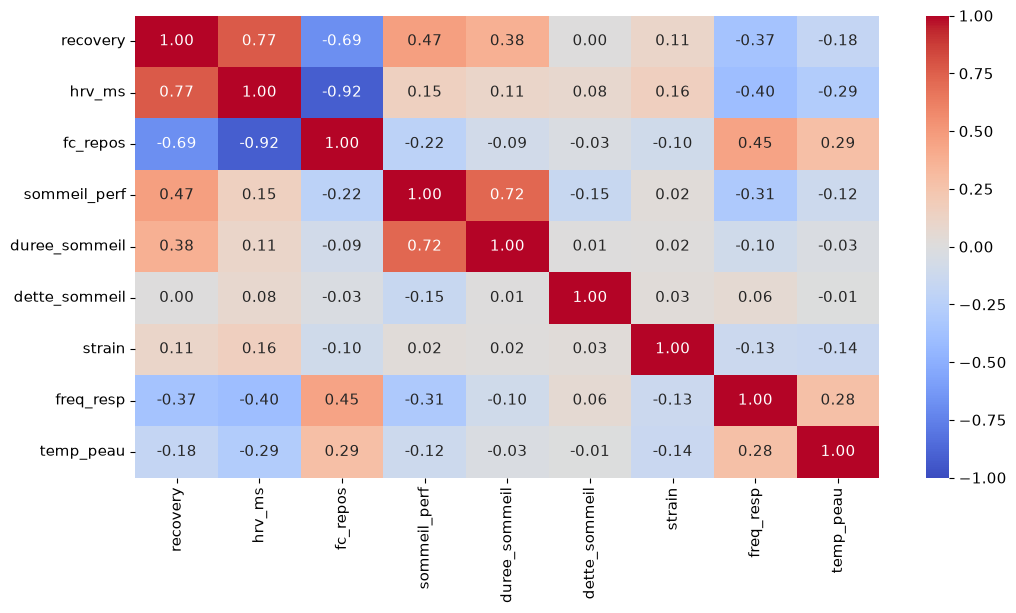

In [47]:
import seaborn as sns
matrice_corr = df.corr()

plt.figure(figsize=(12, 6))
sns.heatmap(matrice_corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)


COEFFICIENT DE CORRÉLATION DE PEARSON : 0.77



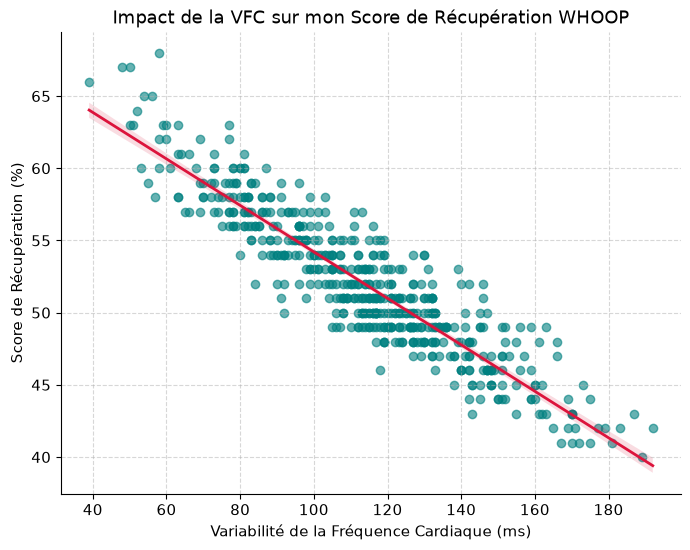

In [53]:
plt.figure(figsize=(8, 6))

# Exemple : Analyser l'impact de la Variabilité de la Fréquence Cardiaque (VFC) sur le score de Récupération
sns.regplot(
    data=df, 
    x='hrv_ms', 
    y='fc_repos',
    scatter_kws={'alpha':0.6, 'color':'teal'}, # Points légèrement transparents
    line_kws={'color':'crimson', 'lw':2}        # Ligne de tendance rouge
)

correlation_num = df['hrv_ms'].corr(df['recovery'])
print("\n" + "="*40)
print(f"COEFFICIENT DE CORRÉLATION DE PEARSON : {correlation_num:.2f}")
print("="*40 + "\n")

plt.title("Impact de la VFC sur mon Score de Récupération WHOOP")
plt.xlabel("Variabilité de la Fréquence Cardiaque (ms)")
plt.ylabel("Score de Récupération (%)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

